# 06 - Validation With Test Data

In [30]:
# Import LIbraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

# Display all columns
pd.set_option('display.max_columns', None)

In [31]:
# Read test data from Parquet file
test_df = pd.read_parquet("test_df.parquet")

test_df.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount,logExposure
362989,3011973.0,0,0.80,E,5,2,30,54,B12,'Regular',4762,R93,NaN,-0.223144
183452,1183012.0,0,0.96,A,7,1,30,85,B1,'Regular',38,R91,NaN,-0.040822
17092,39023.0,0,0.62,B,9,15,27,139,B2,'Regular',65,R24,NaN,-0.478036
325136,2257507.0,0,0.08,E,7,2,57,63,B1,'Regular',3859,R82,NaN,-2.525729
348499,2280841.0,0,0.24,E,5,2,28,76,B1,'Diesel',7259,R31,NaN,-1.427116


In [32]:
# Read df_model from Pickle
df_model = pd.read_pickle("df_model.pickle")

df_model.head()

,ClaimNb,DrivAge,VehAge,BonusMalus,Density,VehPower,Area,Exposure,ClaimAmount,DrivAgeBand,VehAgeBand,BonusMalusBand,DensityBand
547317,0,72,14,50,44.0,4,A,1.00,NaN,"(65, 120]","(10, 20]","(0, 50]","(33.0, 67.0]"
78384,0,35,8,50,359.0,5,C,0.03,NaN,"(25, 35]","(5, 10]","(0, 50]","(214.0, 393.0]"
673782,0,40,1,50,2258.0,7,E,0.74,NaN,"(35, 45]","(-1, 1]","(0, 50]","(1313.0, 2715.0]"
312590,0,26,2,72,3744.0,5,E,0.08,NaN,"(25, 35]","(1, 3]","(70, 80]","(2715.0, 4128.0]"
553703,0,57,4,50,8.0,6,A,0.06,NaN,"(55, 65]","(3, 5]","(0, 50]","(0.999, 33.0]"


In [33]:
# Load the frequency glm
model_freq = sm.load("model_freq.pickle")

# Verify the model loaded
print(model_freq.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:                20109
Model:                            GLM   Df Residuals:                    20088
Model Family:        NegativeBinomial   Df Model:                           20
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -23014.
Date:                Wed, 14 Oct 2026   Deviance:                       11872.
Time:                        22:36:32   Pearson chi2:                 2.77e+04
No. Iterations:                     8   Pseudo R-squ. (CS):            0.09659
Covariance Type:            nonrobust                                         
                                                              coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------

In [34]:
# Prepare Test data for predictions

cols = ["ClaimNb", "DrivAge", "VehAge", "BonusMalus", "Density", "VehPower", "Area", "Exposure", "ClaimAmount"]

df_model_test = test_df[cols].copy()

# Keep valid rows
df_model_test = df_model_test[
    (df_model_test["Exposure"] > 0) &
    (df_model_test["Density"] > 0)
].copy()

# downcast numerics to reduce memory pressure
df_model_test["ClaimNb"] = pd.to_numeric(df_model_test["ClaimNb"], downcast="integer")
df_model_test["DrivAge"] = pd.to_numeric(df_model_test["DrivAge"], downcast="integer")
df_model_test["VehAge"] = pd.to_numeric(df_model_test["VehAge"], downcast="integer")
df_model_test["BonusMalus"] = pd.to_numeric(df_model_test["BonusMalus"], downcast="integer")
df_model_test["Density"] = pd.to_numeric(df_model_test["Density"], downcast="float")
df_model_test["Exposure"] = pd.to_numeric(df_model_test["Exposure"], downcast="float")
df_model_test["ClaimAmount"] = pd.to_numeric(df_model_test["ClaimAmount"], downcast="float")

# calculate log exposure
df_model_test["logExposure"] = np.log(df_model_test["Exposure"])

# convert true categorical fields to category dtype
df_model_test["VehPower"] = pd.Categorical(
    df_model_test["VehPower"],
    categories=df_model["VehPower"].cat.categories
)

df_model_test["Area"] = pd.Categorical(
    df_model_test["Area"],
    categories=df_model_test["Area"].cat.categories
)

# bin continuous variables
df_model_test["DrivAgeBand"] = pd.cut(
    df_model_test["DrivAge"],
    bins=[17, 25, 35, 45, 55, 65, 120]
)

df_model_test["VehAgeBand"] = pd.cut(
    df_model_test["VehAge"],
    bins=[-1, 1, 3, 5, 10, 20, 100]
)

df_model_test["BonusMalusBand"] = pd.cut(
    df_model_test["BonusMalus"],
    bins=[0, 50, 60, 70, 80, 100, 200]
)

# use density bins from training data
# preserve the exact interval categories used during training
density_categories = df_model["DensityBand"].cat.categories

df_model_test["DensityBand"] = pd.cut(
    df_model_test["Density"],
    bins=density_categories
)

# check missing values in transformed variables
print(
    df_model_test[
        ["VehPower", "Area", "DrivAgeBand", "VehAgeBand",
         "BonusMalusBand", "DensityBand"]
    ].isna().sum()
)

# review prepared test data
print(df_model_test.head())

VehPower          0
Area              0
DrivAgeBand       0
VehAgeBand        0
BonusMalusBand    2
DensityBand       0
dtype: int64
        ClaimNb  DrivAge  VehAge  BonusMalus  Density VehPower Area  Exposure  \
362989        0       30       2          54   4762.0        5    E      0.80   
183452        0       30       1          85     38.0        7    A      0.96   
17092         0       27      15         139     65.0        9    B      0.62   
325136        0       57       2          63   3859.0        7    E      0.08   
348499        0       28       2          76   7259.0        5    E      0.24   

        ClaimAmount  logExposure DrivAgeBand VehAgeBand BonusMalusBand  \
362989          NaN    -0.223144    (25, 35]     (1, 3]       (50, 60]   
183452          NaN    -0.040822    (25, 35]    (-1, 1]      (80, 100]   
17092           NaN    -0.478036    (25, 35]   (10, 20]     (100, 200]   
325136          NaN    -2.525729    (55, 65]     (1, 3]       (60, 70]   
348499    

In [35]:
# Combine Driver Age Band 35 - 45 with the reference (17 - 25)
# Required for consistency with the model
print(df_model_test["DrivAgeBand"].cat.categories)

# Combine
df_model_test = df_model_test.copy()

# Convert to string for easy mapping
df_model_test["DrivAgeBand_str"] = df_model_test["DrivAgeBand"].astype(str)

# Get reference band from training data
ref_band = str(df_model["DrivAgeBand"].cat.categories[0])

# Replace (35,45] with reference
df_model_test.loc[
    df_model_test["DrivAgeBand_str"] == "(35, 45]",
    "DrivAgeBand_str"
] = ref_band

# Create new combined variable
df_model_test["DrivAgeBand_combined"] = df_model_test["DrivAgeBand_str"]

# Check
print(
    df_model_test[["DrivAgeBand", "DrivAgeBand_combined"]]
    .drop_duplicates()
    .sort_values("DrivAgeBand_combined")
)

IntervalIndex([(17, 25], (25, 35], (35, 45], (45, 55], (55, 65], (65, 120]], dtype='interval[int64, right]')
       DrivAgeBand DrivAgeBand_combined
291449    (35, 45]             (17, 25]
566767    (17, 25]             (17, 25]
362989    (25, 35]             (25, 35]
148811    (45, 55]             (45, 55]
325136    (55, 65]             (55, 65]
13493    (65, 120]            (65, 120]


In [36]:
# Customize VehPower to also be consistent

df_model_test = df_model_test.copy()

# Ensure string form
df_model_test["VehPower_str"] = df_model_test["VehPower"].astype(int).astype(str)

# Create 2-group structure
df_model_test["VehPower_2grp"] = "Base"  # 4–7 and 12–15
df_model_test.loc[
    df_model_test["VehPower_str"].isin(["8", "9", "10", "11"]),
    "VehPower_2grp"
] = "High_8_11"

# Set reference = Base
import pandas as pd

df_model_test["VehPower_2grp"] = pd.Categorical(
    df_model_test["VehPower_2grp"],
    categories=["Base", "High_8_11"],
    ordered=True
)

# Check grouping
vehpower_summary_test = (
    df_model_test.groupby("VehPower_2grp", observed=True)
    .agg(
        claims=("ClaimNb", "sum"),
        exposure=("Exposure", "sum")
    )
    .reset_index()
)

vehpower_summary_test["frequency"] = (
    vehpower_summary_test["claims"] / vehpower_summary_test["exposure"]
)

print(vehpower_summary_test)

  VehPower_2grp  claims      exposure  frequency
0          Base    9780  89264.578125   0.109562
1     High_8_11    2076  18564.310547   0.111827


In [37]:
# Check required model predictors
required_cols = [
    "DrivAgeBand_combined",
    "VehAgeBand",
    "BonusMalusBand",
    "VehPower_2grp",
    "Area",
    "Exposure",
    "logExposure"
]

print(df_model_test[required_cols].isna().sum())

# Check valid exposure
print("Invalid exposure:",
      (df_model_test["Exposure"] <= 0).sum())

DrivAgeBand_combined    0
VehAgeBand              0
BonusMalusBand          2
VehPower_2grp           0
Area                    0
Exposure                0
logExposure             0
dtype: int64
Invalid exposure: 0


In [38]:
# Identify observations with missing BonusMalusBand
print(
    df_model_test.loc[
        df_model_test["BonusMalusBand"].isna(),
        ["BonusMalus", "BonusMalusBand", "ClaimNb", "Exposure"]
    ]
)

# Remove observations outside the BonusMalus bands
# used during model training
df_model_test = df_model_test[
    df_model_test["BonusMalusBand"].notna()
].copy()

# Confirm no missing BonusMalus bands remain
print(df_model_test["BonusMalusBand"].isna().sum())

# Confirm remaining observations
print("Test observations:", len(df_model_test))

        BonusMalus BonusMalusBand  ClaimNb  Exposure
131852         208            NaN        1      0.25
66645          230            NaN        0      0.25
0
Test observations: 203852


In [39]:
# Generate predictions using the fitted GLM

# Predict expected claim counts
df_model_test["PredictedClaims"] = model_freq.predict(
    df_model_test,
    offset=df_model_test["logExposure"]
)

# Calculate annualized predicted claim frequency
df_model_test["PredictedFrequency"] = (
    df_model_test["PredictedClaims"] /
    df_model_test["Exposure"]
)

# Review the predictions
print(
    df_model_test[
        ["ClaimNb", "Exposure", "PredictedClaims", "PredictedFrequency"]
    ].head(10)
)

        ClaimNb  Exposure  PredictedClaims  PredictedFrequency
362989        0      0.80         0.069970            0.087463
183452        0      0.96         0.199354            0.207660
17092         0      0.62         0.172964            0.278975
325136        0      0.08         0.014828            0.185345
348499        0      0.24         0.029730            0.123874
160392        0      1.00         0.053350            0.053350
566908        0      0.96         0.131610            0.137094
148811        0      0.30         0.030024            0.100081
603553        0      0.71         0.148264            0.208823
160299        0      1.00         0.083457            0.083457


In [40]:
# Check for invalid predictions
print("Missing predictions:",
      df_model_test["PredictedClaims"].isna().sum())

print("Infinite predictions:",
      np.isinf(df_model_test["PredictedClaims"]).sum())

print("Negative predictions:",
      (df_model_test["PredictedClaims"] < 0).sum())

# Summary statistics
print(
    df_model_test[
        ["PredictedClaims", "PredictedFrequency"]
    ].describe()
)

Missing predictions: 0
Infinite predictions: 0
Negative predictions: 0
       PredictedClaims  PredictedFrequency
count    203852.000000       203852.000000
mean          0.058259            0.119042
std           0.049807            0.064454
min           0.000093            0.026366
25%           0.018750            0.077688
50%           0.052086            0.099470
75%           0.082977            0.141297
max           0.829970            0.960696


In [41]:
# Calculate overall actual vs predicted claim frequency to validate

actual_claims = df_model_test["ClaimNb"].sum()
predicted_claims = df_model_test["PredictedClaims"].sum()
total_exposure = df_model_test["Exposure"].sum()

# Calculate annual claim frequencies
actual_frequency = actual_claims / total_exposure
predicted_frequency = predicted_claims / total_exposure

# Calculate Actual-to-Expected ratio
ae_ratio = actual_claims / predicted_claims

# Display results
print(f"Total Exposure: {total_exposure:,.2f}")
print(f"Actual Claims: {actual_claims:,.0f}")
print(f"Predicted Claims: {predicted_claims:,.2f}")
print(f"Actual Frequency: {actual_frequency:.4f}")
print(f"Predicted Frequency: {predicted_frequency:.4f}")
print(f"Actual / Expected Ratio: {ae_ratio:.4f}")

# Actual / Expected Ratio for the number of claims was 0.9982, which is very close to a 100%
# This suggests the model calibrates well to the test dataset.

Total Exposure: 107,828.39
Actual Claims: 11,855
Predicted Claims: 11,876.27
Actual Frequency: 0.1099
Predicted Frequency: 0.1101
Actual / Expected Ratio: 0.9982


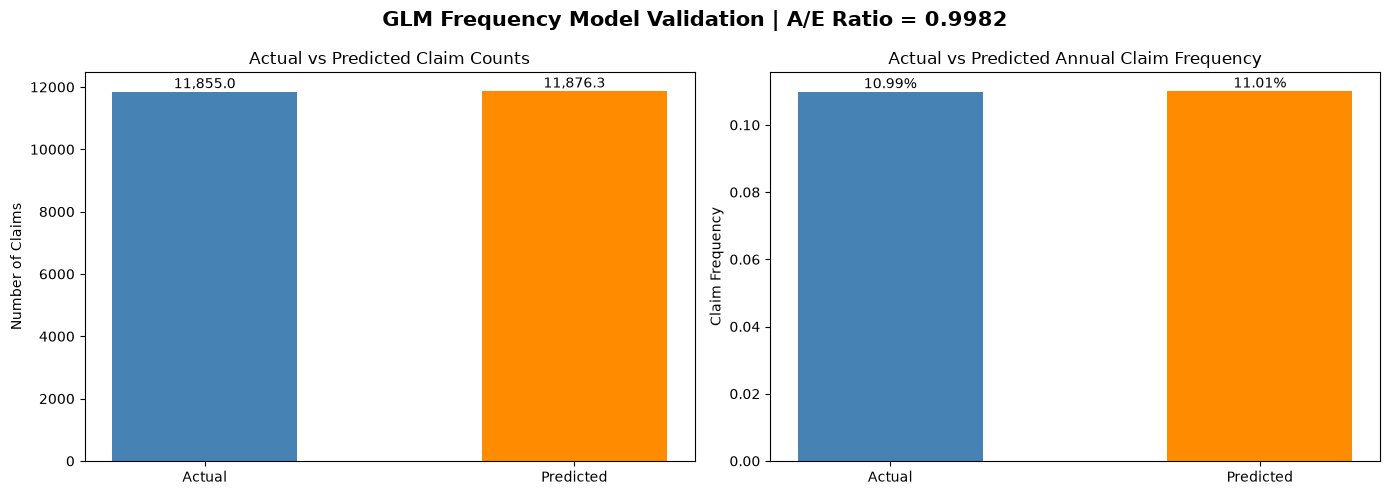

In [42]:
# Visualize overall actual vs predicted claim frequency

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ["steelblue", "darkorange"]

# Chart 1: Actual vs Predicted Claim Counts
axes[0].bar(
    ["Actual", "Predicted"],
    [actual_claims, predicted_claims],
    color=colors,
    width=0.5
)

axes[0].set_title("Actual vs Predicted Claim Counts")
axes[0].set_ylabel("Number of Claims")

for i, value in enumerate([actual_claims, predicted_claims]):
    axes[0].text(
        i, value,
        f"{value:,.1f}",
        ha="center",
        va="bottom"
    )

# Chart 2: Actual vs Predicted Claim Frequency
axes[1].bar(
    ["Actual", "Predicted"],
    [actual_frequency, predicted_frequency],
    color=colors,
    width=0.5
)

axes[1].set_title("Actual vs Predicted Annual Claim Frequency")
axes[1].set_ylabel("Claim Frequency")

for i, value in enumerate([actual_frequency, predicted_frequency]):
    axes[1].text(
        i, value,
        f"{value:.2%}",
        ha="center",
        va="bottom"
    )

# Display A/E Ratio
fig.suptitle(
    f"GLM Frequency Model Validation | A/E Ratio = {ae_ratio:.4f}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [43]:
# Now, we validate by rating factors

# Validate actual vs predicted frequency by Driver Age Band

age_validation = (
    df_model_test.groupby("DrivAgeBand_combined")
    .agg(
        Exposure=("Exposure", "sum"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum")
    )
)

# Calculate actual and predicted frequency
age_validation["ActualFrequency"] = (
    age_validation["ActualClaims"] / age_validation["Exposure"]
)

age_validation["PredictedFrequency"] = (
    age_validation["PredictedClaims"] / age_validation["Exposure"]
)

# Calculate Actual-to-Expected ratio
age_validation["AE_Ratio"] = (
    age_validation["ActualClaims"] /
    age_validation["PredictedClaims"]
)

print(age_validation.round(4))

                          Exposure  ActualClaims  PredictedClaims  \
DrivAgeBand_combined                                                
(17, 25]              31339.580078          3588        3680.1539   
(25, 35]              20827.351562          2127        2256.7526   
(45, 55]              26759.238281          3284        2976.8661   
(55, 65]              15490.007812          1484        1542.3151   
(65, 120]             13412.209961          1372        1420.1845   

                      ActualFrequency  PredictedFrequency  AE_Ratio  
DrivAgeBand_combined                                                 
(17, 25]                       0.1145              0.1174    0.9750  
(25, 35]                       0.1021              0.1084    0.9425  
(45, 55]                       0.1227              0.1112    1.1032  
(55, 65]                       0.0958              0.0996    0.9622  
(65, 120]                      0.1023              0.1059    0.9661  


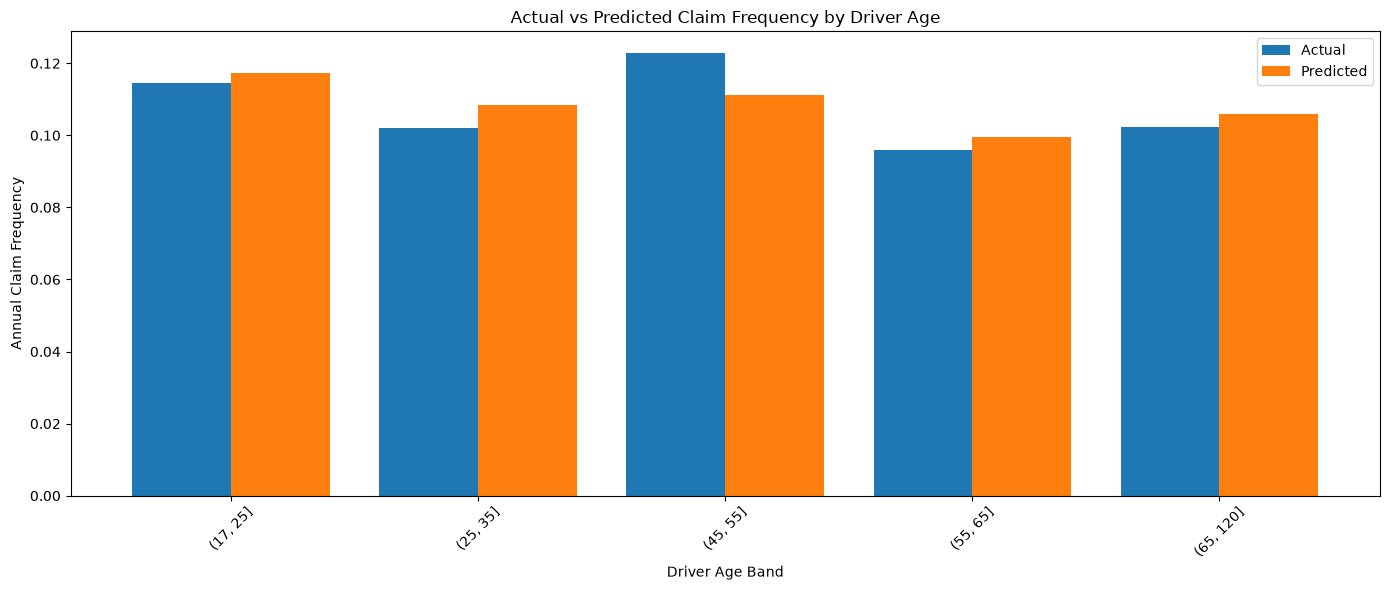

In [44]:
# Plot actual vs predicted frequency by Driver Age Band

age_validation[
    ["ActualFrequency", "PredictedFrequency"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Actual vs Predicted Claim Frequency by Driver Age")
plt.xlabel("Driver Age Band")
plt.ylabel("Annual Claim Frequency")
plt.xticks(rotation=45)
plt.legend(["Actual", "Predicted"])
plt.tight_layout()
plt.show()

In [45]:
# Validate actual vs predicted frequency by Vehicle Age Band

vehage_validation = (
    df_model_test.groupby("VehAgeBand", observed=True)
    .agg(
        Exposure=("Exposure", "sum"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum")
    )
)

# Calculate actual and predicted frequency
vehage_validation["ActualFrequency"] = (
    vehage_validation["ActualClaims"] / vehage_validation["Exposure"]
)

vehage_validation["PredictedFrequency"] = (
    vehage_validation["PredictedClaims"] / vehage_validation["Exposure"]
)

# Calculate Actual-to-Expected ratio
vehage_validation["AE_Ratio"] = (
    vehage_validation["ActualClaims"] / vehage_validation["PredictedClaims"]
)

print(vehage_validation.round(4))

# Vehicle Age 20-100 has the most variation, but it also has a small number of actual claims
# This could make thje estimate less stable

                Exposure  ActualClaims  PredictedClaims  ActualFrequency  \
VehAgeBand                                                                 
(-1, 1]     14904.017578          2582        2476.5132           0.1732   
(1, 3]      16761.244141          1651        1713.3202           0.0985   
(3, 5]      13842.678711          1442        1448.2575           0.1042   
(5, 10]     29759.865234          3171        3394.7239           0.1066   
(10, 20]    31020.666016          2905        2762.7735           0.0936   
(20, 100]    1539.919556           104          80.6840           0.0675   

            PredictedFrequency  AE_Ratio  
VehAgeBand                                
(-1, 1]                 0.1662    1.0426  
(1, 3]                  0.1022    0.9636  
(3, 5]                  0.1046    0.9957  
(5, 10]                 0.1141    0.9341  
(10, 20]                0.0891    1.0515  
(20, 100]               0.0524    1.2890  


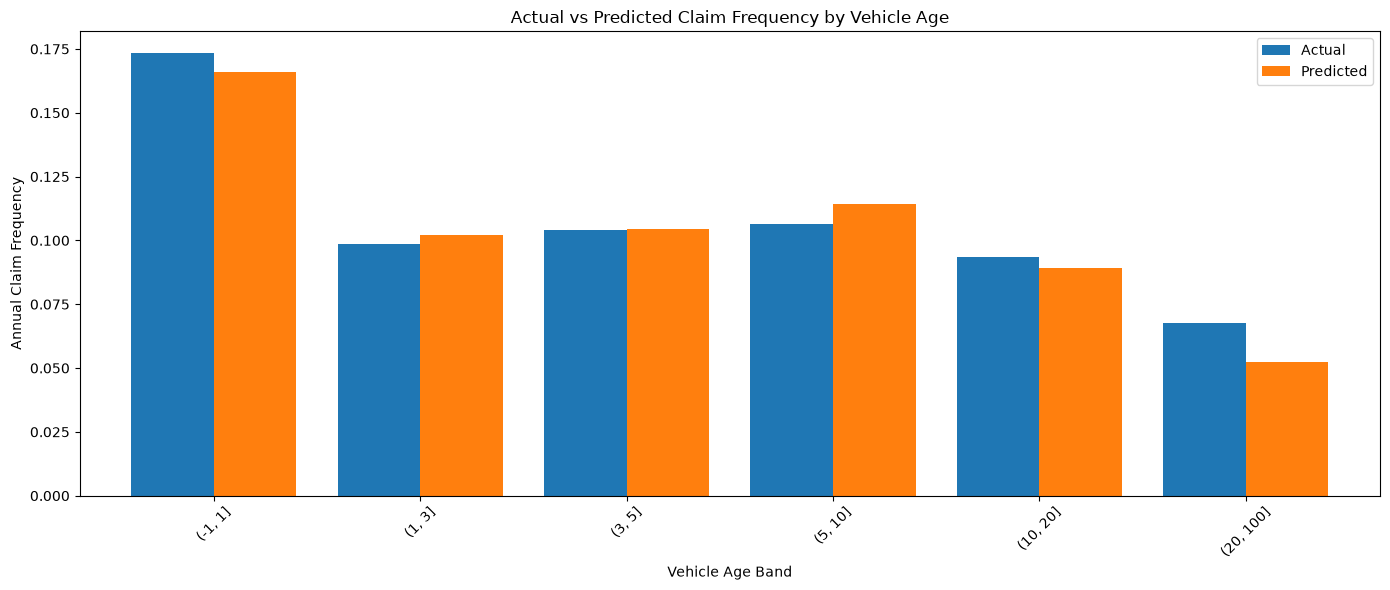

In [46]:
# Plot actual vs predicted frequency by Vehicle Age Band
vehage_validation[
    ["ActualFrequency", "PredictedFrequency"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Actual vs Predicted Claim Frequency by Vehicle Age")
plt.xlabel("Vehicle Age Band")
plt.ylabel("Annual Claim Frequency")
plt.xticks(rotation=45)
plt.legend(["Actual", "Predicted"])
plt.tight_layout()
plt.show()

In [47]:
# Validate actual vs predicted frequency by Bonus-Malus Band

bonusmalus_validation = (
    df_model_test.groupby("BonusMalusBand", observed=True)
    .agg(
        Exposure=("Exposure", "sum"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum")
    )
)

# Calculate actual and predicted frequency
bonusmalus_validation["ActualFrequency"] = (
    bonusmalus_validation["ActualClaims"] / bonusmalus_validation["Exposure"]
)

bonusmalus_validation["PredictedFrequency"] = (
    bonusmalus_validation["PredictedClaims"] / bonusmalus_validation["Exposure"]
)

# Calculate Actual-to-Expected ratio
bonusmalus_validation["AE_Ratio"] = (
    bonusmalus_validation["ActualClaims"] / bonusmalus_validation["PredictedClaims"]
)

print(bonusmalus_validation.round(4))

                    Exposure  ActualClaims  PredictedClaims  ActualFrequency  \
BonusMalusBand                                                                 
(0, 50]         67633.726562          5944        5773.9542           0.0879   
(50, 60]        14459.528320          1485        1514.1044           0.1027   
(60, 70]         7937.199219          1193        1241.5503           0.1503   
(70, 80]         8112.473633          1128        1168.4633           0.1390   
(80, 100]        8593.141602          1648        1713.2675           0.1918   
(100, 200]       1092.319702           457         464.9326           0.4184   

                PredictedFrequency  AE_Ratio  
BonusMalusBand                                
(0, 50]                     0.0854    1.0295  
(50, 60]                    0.1047    0.9808  
(60, 70]                    0.1564    0.9609  
(70, 80]                    0.1440    0.9654  
(80, 100]                   0.1994    0.9619  
(100, 200]                  0.

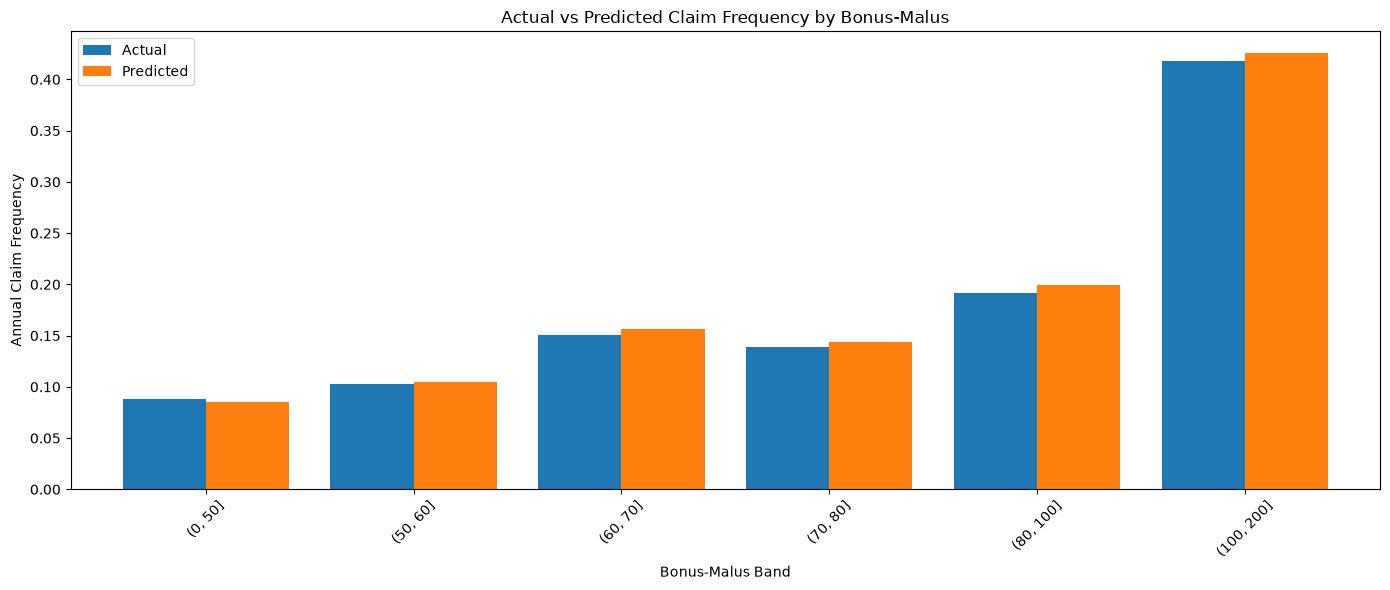

In [48]:
# Plot actual vs predicted frequency by Bonus-Malus Band
bonusmalus_validation[
    ["ActualFrequency", "PredictedFrequency"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Actual vs Predicted Claim Frequency by Bonus-Malus")
plt.xlabel("Bonus-Malus Band")
plt.ylabel("Annual Claim Frequency")
plt.xticks(rotation=45)
plt.legend(["Actual", "Predicted"])
plt.tight_layout()
plt.show()

In [49]:
# Validate actual vs predicted frequency by Vehicle Power Group

vehpower_validation = (
    df_model_test.groupby("VehPower_2grp", observed=True)
    .agg(
        Exposure=("Exposure", "sum"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum")
    )
)

# Calculate actual and predicted frequency
vehpower_validation["ActualFrequency"] = (
    vehpower_validation["ActualClaims"] / vehpower_validation["Exposure"]
)

vehpower_validation["PredictedFrequency"] = (
    vehpower_validation["PredictedClaims"] / vehpower_validation["Exposure"]
)

# Calculate Actual-to-Expected ratio
vehpower_validation["AE_Ratio"] = (
    vehpower_validation["ActualClaims"] / vehpower_validation["PredictedClaims"]
)

print(vehpower_validation.round(4))

                   Exposure  ActualClaims  PredictedClaims  ActualFrequency  \
VehPower_2grp                                                                 
Base           89264.328125          9779        9728.1193           0.1096   
High_8_11      18564.060547          2076        2148.1529           0.1118   

               PredictedFrequency  AE_Ratio  
VehPower_2grp                                
Base                       0.1090    1.0052  
High_8_11                  0.1157    0.9664  


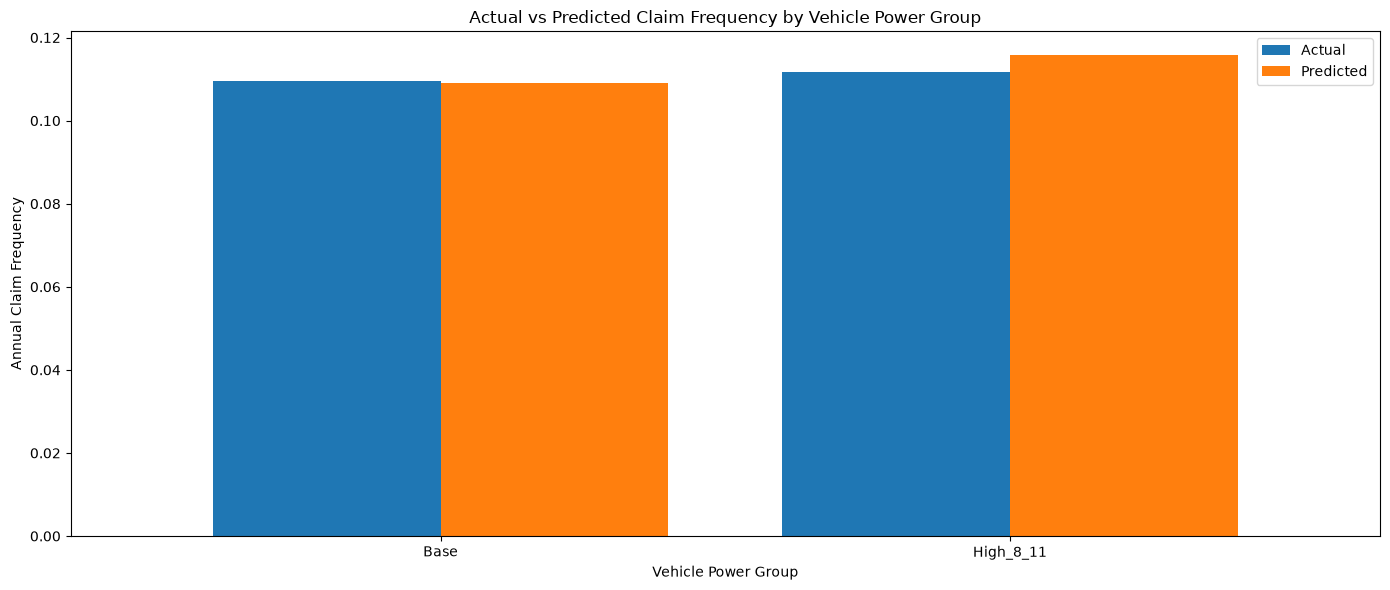

In [50]:
# Plot actual vs predicted frequency by Vehicle Power Group
vehpower_validation[
    ["ActualFrequency", "PredictedFrequency"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Actual vs Predicted Claim Frequency by Vehicle Power Group")
plt.xlabel("Vehicle Power Group")
plt.ylabel("Annual Claim Frequency")
plt.xticks(rotation=0)
plt.legend(["Actual", "Predicted"])
plt.tight_layout()
plt.show()

In [51]:
# Validate actual vs predicted frequency by Area

area_validation = (
    df_model_test.groupby("Area", observed=True)
    .agg(
        Exposure=("Exposure", "sum"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum")
    )
)

# Calculate actual and predicted frequency
area_validation["ActualFrequency"] = (
    area_validation["ActualClaims"] / area_validation["Exposure"]
)

area_validation["PredictedFrequency"] = (
    area_validation["PredictedClaims"] / area_validation["Exposure"]
)

# Calculate Actual-to-Expected ratio
area_validation["AE_Ratio"] = (
    area_validation["ActualClaims"] / area_validation["PredictedClaims"]
)

print(area_validation.round(4))

# Area F has few claims, so the estimate may be unstable
# Area D, on the other hand, has a higher variance than we would have liked to see
# Area B also has a higher variance than desired, but in the other direction

          Exposure  ActualClaims  PredictedClaims  ActualFrequency  \
Area                                                                 
A     18585.982422          1625        1622.5045           0.0874   
B     12948.343750          1172        1296.1642           0.0905   
C     31506.410156          3129        3233.0383           0.0993   
D     23199.488281          3020        2762.1765           0.1302   
E     19112.728516          2518        2594.7908           0.1317   
F      2475.438477           391         367.5979           0.1580   

      PredictedFrequency  AE_Ratio  
Area                                
A                 0.0873    1.0015  
B                 0.1001    0.9042  
C                 0.1026    0.9678  
D                 0.1191    1.0933  
E                 0.1358    0.9704  
F                 0.1485    1.0637  


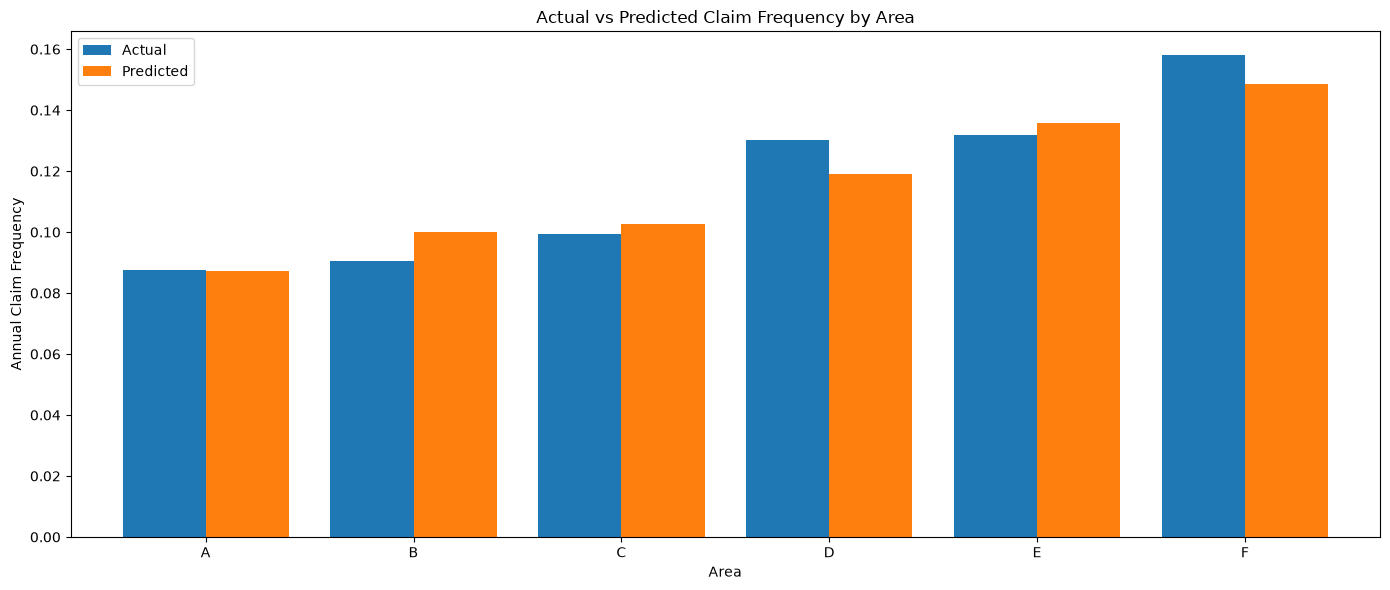

In [52]:
# Plot actual vs predicted frequency by Area
area_validation[
    ["ActualFrequency", "PredictedFrequency"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Actual vs Predicted Claim Frequency by Area")
plt.xlabel("Area")
plt.ylabel("Annual Claim Frequency")
plt.xticks(rotation=0)
plt.legend(["Actual", "Predicted"])
plt.tight_layout()
plt.show()

In [53]:
# Additional Validation

# Create a separate validation dataset
df_decile = df_model_test.copy()

# Rank policies by predicted annual claim frequency
# Rank helps handle tied predicted frequencies
df_decile["RiskDecile"] = pd.qcut(
    df_decile["PredictedFrequency"].rank(method="first"),
    q=10,
    labels=range(1, 11)
).astype(int)

# Check number of policies in each decile
print(
    df_decile["RiskDecile"]
    .value_counts()
    .sort_index()
)

RiskDecile
1     20386
2     20385
3     20385
4     20385
5     20385
6     20385
7     20385
8     20385
9     20385
10    20386
Name: count, dtype: int64


In [54]:
# Calculate validation metrics by risk decile
decile_validation = (
    df_decile.groupby("RiskDecile")
    .agg(
        Policies=("ClaimNb", "size"),
        Exposure=("Exposure", "sum"),
        ActualClaims=("ClaimNb", "sum"),
        PredictedClaims=("PredictedClaims", "sum")
    )
)

# Actual claim frequency
decile_validation["ActualFrequency"] = (
    decile_validation["ActualClaims"] /
    decile_validation["Exposure"]
)

# Predicted claim frequency
decile_validation["PredictedFrequency"] = (
    decile_validation["PredictedClaims"] /
    decile_validation["Exposure"]
)

# Actual-to-Expected ratio
decile_validation["AE_Ratio"] = (
    decile_validation["ActualClaims"] /
    decile_validation["PredictedClaims"]
)

print(decile_validation.round(4))

            Policies      Exposure  ActualClaims  PredictedClaims  \
RiskDecile                                                          
1              20386  13215.870117           648         755.0924   
2              20385  12868.678711           875         906.8515   
3              20385  12405.390625          1227         974.9732   
4              20385  12313.958008          1001        1054.3074   
5              20385  11843.622070          1001        1112.3130   
6              20385  10753.457031          1088        1140.6056   
7              20385   8892.627930          1177        1095.6871   
8              20385   8996.802734          1334        1265.8583   
9              20385   8419.943359          1473        1424.8236   
10             20386   8118.039062          2031        2145.7603   

            ActualFrequency  PredictedFrequency  AE_Ratio  
RiskDecile                                                 
1                    0.0490              0.0571    

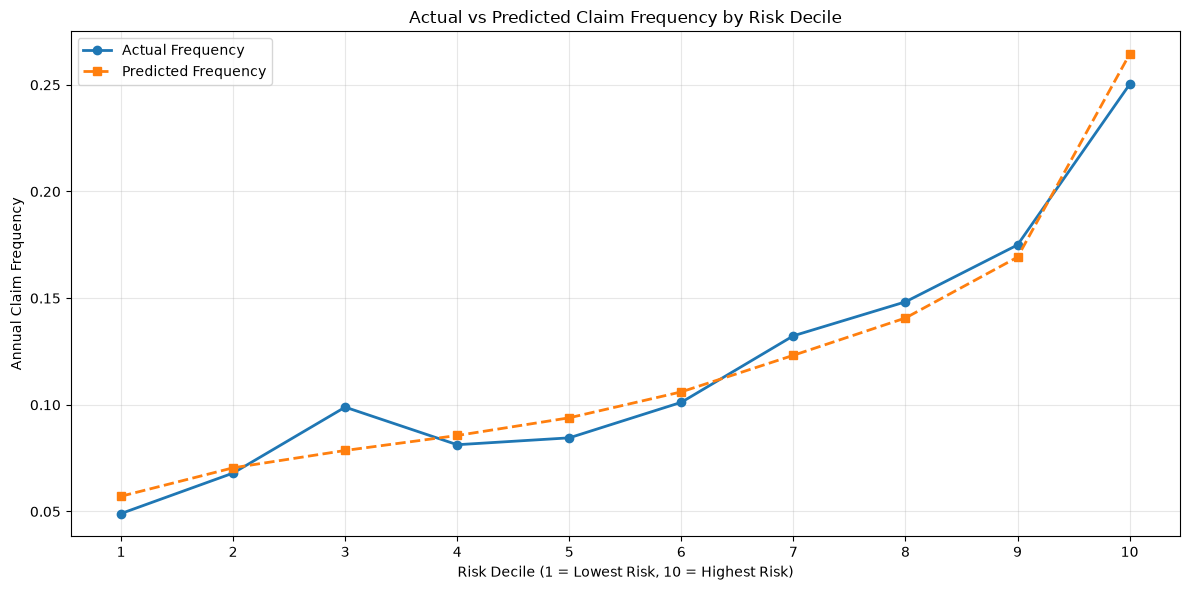

In [55]:
plt.figure(figsize=(12, 6))

plt.plot(
    decile_validation.index,
    decile_validation["ActualFrequency"],
    marker="o",
    linewidth=2,
    label="Actual Frequency"
)

plt.plot(
    decile_validation.index,
    decile_validation["PredictedFrequency"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Predicted Frequency"
)

plt.title("Actual vs Predicted Claim Frequency by Risk Decile")
plt.xlabel("Risk Decile (1 = Lowest Risk, 10 = Highest Risk)")
plt.ylabel("Annual Claim Frequency")

plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [56]:
## Overall Modeling Results
# Overall calibration is excellent: A/E = 0.9982
# Bonus-Malus shows consistently good calibration
# Vehicle power shows good calibration
# Driver Age shows underprediction for ages 45–55
# Area shows underprediction in Area D and overprediction in Area B
# Risk differentiation shows strong separation between lowest and highest deciles.
# Calibration by risk level is generally reasonable, but uneven